# Serie III.1 · Perfiles de países y productividad relativa de Guatemala

**Pregunta:** qué perfiles productivos aparecen en 1961–2023, dónde está Guatemala y qué países permiten una comparación defendible.
Se emplean las fuentes de caña verificadas en el notebook 13. La comparación de productividad territorial no mide ventaja comparativa económica: faltan costos de oportunidad, clima, agua, suelo, trabajo y capital.

Las [respuestas de la prueba](../docs/respuestas-prueba.md) y las [conclusiones de Serie III](../docs/conclusiones-serie-III.md) presentan resultados y límites.

## Representación y cobertura

Se exige operación positiva en los tres indicadores en al menos 60 % de cada bloque: 1961–1970, 1971–1980, 1981–1990, 1991–2000, 2001–2010 y 2011–2023; además cuatro de los cinco años 2019–2023. Ceros y ausencias siguen en el crudo: los logs requieren valores positivos, sin imputación.

Cada área tiene seis rasgos: log de mediana reciente de superficie/rendimiento, tendencia anual equivalente de sus medianas por bloque y variabilidad robusta de cambios logarítmicos anuales consecutivos. Tendencia = 100×(exp(pendiente)−1); variabilidad = 100×1.4826×MAD de cambios log, sin interpretación como probabilidad normal. La producción caracteriza perfiles después, porque está ligada a área×rendimiento.

Se estandarizan los seis rasgos. K-means compara K=2/3/4, exige al menos cinco áreas por grupo y elige el menor K a ≤0.02 de la mejor silueta admisible. Es una regla descriptiva, no clases naturales certificadas ni una selección basada en dónde queda Guatemala.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz = Path.cwd()
if raiz.name == 'notebooks': raiz = raiz.parent
if str(raiz) not in sys.path: sys.path.insert(0,str(raiz))
from scripts.segmentar_paises_serie3 import ejecutar
decision = ejecutar(raiz)
salida = raiz / 'outputs/serie3_segmentacion'
f = pd.read_csv(salida / 'paises_y_rasgos.csv').set_index('area')
display(pd.read_csv(salida / 'eleccion_k.csv').round(4))
display(pd.read_csv(salida / 'perfiles.csv').round(3))
criterios = pd.read_csv(salida / 'elegibilidad.csv')
print('Áreas elegibles:',len(f),'| Fuera por cobertura:',int((~criterios.elegible).sum()))
display(criterios[~criterios.elegible][['area','motivo']])

,k,silueta,menor_grupo,inercia
0,2,0.2808,18,336.4444
1,3,0.2013,18,272.9386
2,4,0.1869,10,241.3658


,grupo,area_reciente_ha,rendimiento_reciente_kg_ha,produccion_reciente_t,log_area_reciente,tendencia_area_pct,variabilidad_area_log,log_rendimiento_reciente,tendencia_rendimiento_pct,variabilidad_rendimiento_log,tendencia_produccion_pct,n_areas
0,1,4743.5,26959.45,123130.165,8.402,0.437,2.902,10.202,-0.266,2.533,0.223,18
1,2,74064.5,66170.75,5712961.500,11.213,1.452,7.453,11.100,0.676,7.761,2.246,56


Áreas elegibles: 74 | Fuera por cobertura: 38


,area,motivo
2,Antigua and Barbuda,cobertura_insuficiente_1971_1980;cobertura_ins...
5,Bahamas,cobertura_insuficiente_1961_1970
9,Benin,cobertura_insuficiente_1961_1970;cobertura_ins...
10,Bhutan,cobertura_insuficiente_1961_1970;cobertura_ins...
13,Brunei Darussalam,cobertura_insuficiente_1961_1970;cobertura_ins...
14,Burkina Faso,cobertura_insuficiente_1961_1970
15,Burundi,cobertura_insuficiente_1961_1970
19,Central African Republic,cobertura_insuficiente_1961_1970;cobertura_ins...
27,Côte d'Ivoire,cobertura_insuficiente_1961_1970
29,Djibouti,cobertura_insuficiente_1961_1970;cobertura_ins...


## Perfiles productivos

El modelo identifica dos perfiles amplios. El de menor rendimiento/escala tiene 18 áreas; el otro 56 e incluye Guatemala. La silueta es aproximadamente 0.281: hay solapamiento. La menor variabilidad del primer perfil también coincide con menor proporción de datos oficiales; puede reflejar suavización de estimaciones y no mayor estabilidad real.

Una pertenencia compartida por decenas de países no basta para definir pares cercanos. Los círculos negros muestran los vecinos por estructura territorial y la estrella a Guatemala.

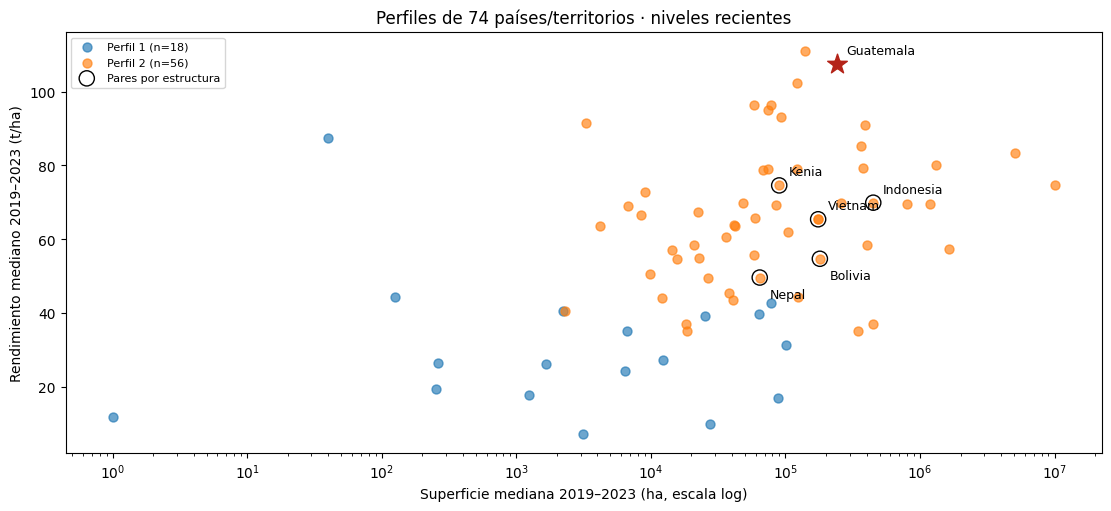

In [2]:
pares = pd.read_csv(salida / 'pares_y_candidatos.csv').set_index('area')
elegidos = pares.index[pares.elegido].tolist()
nombres = {'Guatemala':'Guatemala','Indonesia':'Indonesia','Bolivia (Plurinational State of)':'Bolivia','Nepal':'Nepal','Kenya':'Kenia','Viet Nam':'Vietnam'}
fig, ax = plt.subplots(figsize=(11,5),constrained_layout=True)
for grupo, g in f.groupby('grupo'):
    ax.scatter(g.area_reciente_ha,g.rendimiento_reciente_kg_ha/1000,label=f'Perfil {grupo} (n={len(g)})',alpha=.65,s=42)
ax.scatter(f.loc[elegidos,'area_reciente_ha'],f.loc[elegidos,'rendimiento_reciente_kg_ha']/1000,facecolors='none',edgecolors='black',s=120,label='Pares por estructura')
ax.scatter(f.loc['Guatemala','area_reciente_ha'],f.loc['Guatemala','rendimiento_reciente_kg_ha']/1000,marker='*',color='#b42318',s=220,zorder=5)
desplazamientos = {'Guatemala':(7,7),'Indonesia':(7,7),'Bolivia (Plurinational State of)':(7,-15),'Nepal':(7,-15),'Kenya':(7,7),'Viet Nam':(7,7)}
for area in ['Guatemala',*elegidos]:
    ax.annotate(nombres[area],(f.loc[area,'area_reciente_ha'],f.loc[area,'rendimiento_reciente_kg_ha']/1000),xytext=desplazamientos[area],textcoords='offset points',fontsize=9)
ax.set(xscale='log',xlabel='Superficie mediana 2019–2023 (ha, escala log)',ylabel='Rendimiento mediano 2019–2023 (t/ha)',title='Perfiles de 74 países/territorios · niveles recientes')
ax.legend(fontsize=8,loc='upper left')
fig.savefig(salida / 'perfiles_paises.png',dpi=160)
plt.show()

## Pares sin seleccionar por el rendimiento que se quiere comparar

La referencia usa superficie mediana, tendencia y variabilidad de superficie, estandarizadas sobre las áreas elegibles. No incluye rendimiento ni producción en su distancia. Se admite superficie entre un cuarto y cuatro veces la de Guatemala y se eligen cinco vecinos. Esta amplitud es técnica, no equivalencia de recursos naturales.

Indonesia, Bolivia y Vietnam permanecen al cambiar ventana, cobertura, criterio de variabilidad y límite de superficie. Nepal y Kenia son secundarios: salen cuando se exige superficie entre la mitad y el doble. No se presume semejanza climática, tecnológica o de costos. Las curvas muestran medianas de los bloques, indexadas a 100 en el primero; no interpolan años faltantes.

,distancia,ratio_area_a_GT,area_reciente_ha,rendimiento_reciente_kg_ha,produccion_reciente_t,tendencia_area_pct,tendencia_rendimiento_pct
area,,,,,,,
Guatemala,0.000,1.000,241000.0,107520.6,25845178.00,4.027,0.805
Indonesia,0.213,1.863,449008.0,69929.1,31000000.00,3.744,-1.610
Bolivia (Plurinational State of),0.250,0.747,180065.0,54754.9,10057104.09,3.103,0.553
Nepal,0.344,0.267,64354.0,49674.5,3183943.00,4.066,2.306
Kenya,0.430,0.373,89800.0,74599.9,6810898.00,2.657,0.988
Viet Nam,0.481,0.725,174816.0,65438.3,11534588.71,4.007,1.315


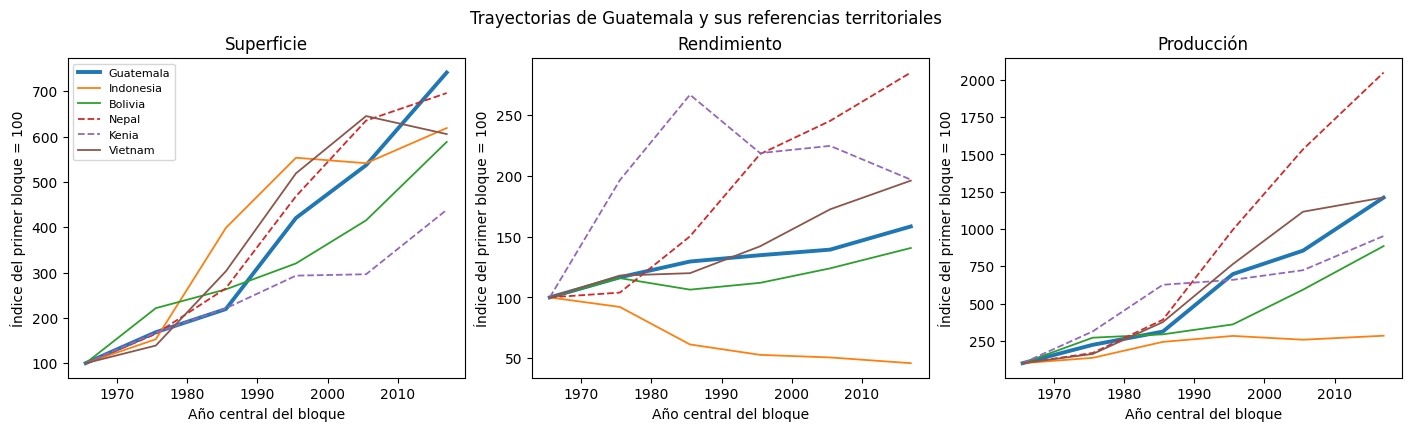

,area,elemento,2019,2023,cambio_2019_2023_pct
0,Bolivia (Plurinational State of),Area harvested,174630.00,176294.00,0.953
1,Bolivia (Plurinational State of),Production,9558472.00,10307308.57,7.834
2,Bolivia (Plurinational State of),Yield,54735.60,58466.60,6.816
3,Guatemala,Area harvested,277762.00,241000.00,-13.235
4,Guatemala,Production,29865166.00,23971750.00,-19.733
5,Guatemala,Yield,107520.60,99467.80,-7.490
6,Indonesia,Area harvested,413054.00,511048.00,23.724
7,Indonesia,Production,29100000.00,31000000.00,6.529
8,Indonesia,Yield,70450.80,60659.70,-13.898
9,Kenya,Area harvested,71935.00,80700.00,12.185


In [3]:
columnas = ['distancia','ratio_area_a_GT','area_reciente_ha','rendimiento_reciente_kg_ha','produccion_reciente_t','tendencia_area_pct','tendencia_rendimiento_pct']
display(pares.loc[['Guatemala',*elegidos],columnas].round(3))
b = pd.read_csv(salida / 'bloques.csv')
fig, axes = plt.subplots(1,3,figsize=(14,4.2),constrained_layout=True)
campos = ['area_mediana_ha','rendimiento_mediano_kg_ha','produccion_mediana_t']
for area in ['Guatemala',*elegidos]:
    g = b[b.area.eq(area)].sort_values('inicio')
    for ax, campo, titulo in zip(axes,campos,['Superficie','Rendimiento','Producción']):
        ax.plot(g.ano_central,100*g[campo]/g[campo].iloc[0],label=nombres[area],lw=2.8 if area=='Guatemala' else 1.3,linestyle='--' if area in ['Nepal','Kenya'] else '-')
        ax.set(title=titulo,xlabel='Año central del bloque',ylabel='Índice del primer bloque = 100')
axes[0].legend(fontsize=8)
fig.suptitle('Trayectorias de Guatemala y sus referencias territoriales')
fig.savefig(salida / 'trayectorias_pares.png',dpi=160)
plt.show()
display(pd.read_csv(salida / 'evolucion_reciente.csv').round(3))

## Productividad territorial relativa

Se compara Guatemala con la mediana y percentil 75 de los cinco pares **en el mismo año**, sin incluirla en la referencia. La mediana de sus cinco cocientes anuales es 1.679 frente a la mediana y 1.534 frente a P75. Son diferencias descriptivas de rendimiento, no ahorro, potencial causal ni probabilidad de superioridad.

Guatemala ocupa el segundo lugar de rendimiento mediano reciente entre las 74 áreas elegibles; no es un ranking mundial sin restricciones. El rendimiento de Guatemala de 2019–2021 es E y su área I. En 2022/2023 ambas son A; la comparación solo-A conserva esos dos años y cuatro referencias oficiales, sin reconstruir los años ausentes.

,ano,n_pares,gt_kg_ha,gt_flag,mediana_pares_kg_ha,p75_pares_kg_ha,ratio_GT_mediana,ratio_GT_p75,solo_oficial
0,2019,5,107520.6,E,64031.40,65961.400,1.6792,1.6301,False
1,2020,5,107269.3,E,62203.00,69929.100,1.7245,1.5340,False
2,2021,5,107585.4,E,64735.50,71713.600,1.6619,1.5002,False
3,2022,5,107688.2,A,61737.30,65438.300,1.7443,1.6456,False
4,2023,5,99467.8,A,60659.70,67749.900,1.6398,1.4682,False
5,2019,4,107520.6,E,NaN,NaN,NaN,NaN,True
6,2020,4,107269.3,E,NaN,NaN,NaN,NaN,True
7,2021,4,107585.4,E,NaN,NaN,NaN,NaN,True
8,2022,4,107688.2,A,59431.20,67728.700,1.8120,1.5900,True
9,2023,4,99467.8,A,63108.25,68024.625,1.5761,1.4622,True


,ano,gt_kg_ha,gt_flag,cambio_anual_GT_pct
0,2019,107520.6,E,NaN
1,2020,107269.3,E,-0.2337
2,2021,107585.4,E,0.2947
3,2022,107688.2,A,0.0956
4,2023,99467.8,A,-7.6335


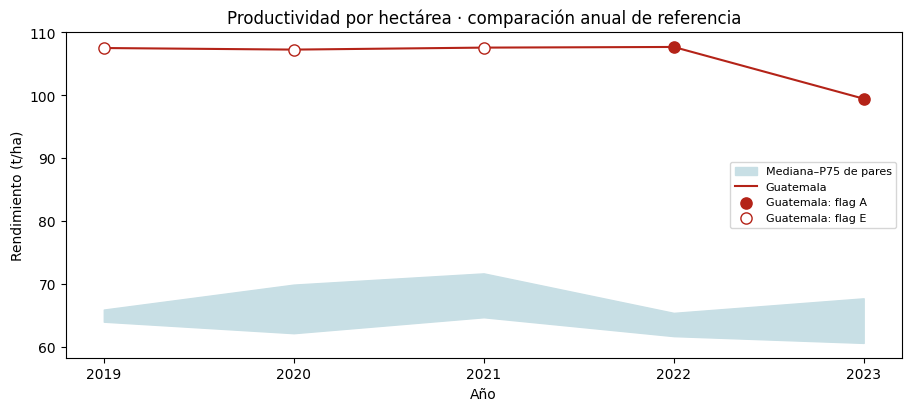

In [4]:
referencia = pd.read_csv(salida / 'referencia_productividad.csv')
display(referencia.round(4))
principal = referencia[~referencia.solo_oficial]
display(principal.assign(cambio_anual_GT_pct=100*principal.gt_kg_ha.pct_change())[['ano','gt_kg_ha','gt_flag','cambio_anual_GT_pct']].round(4))
fig, ax = plt.subplots(figsize=(9,4),constrained_layout=True)
ax.fill_between(principal.ano,principal.mediana_pares_kg_ha/1000,principal.p75_pares_kg_ha/1000,color='#c8dfe5',label='Mediana–P75 de pares')
ax.plot(principal.ano,principal.gt_kg_ha/1000,color='#b42318',label='Guatemala')
for flag, g in principal.groupby('gt_flag'):
    ax.scatter(g.ano,g.gt_kg_ha/1000,facecolors='white' if flag=='E' else '#b42318',edgecolors='#b42318',s=65,zorder=4,label=f'Guatemala: flag {flag}')
ax.set(xlabel='Año',ylabel='Rendimiento (t/ha)',title='Productividad por hectárea · comparación anual de referencia')
ax.set_xticks(principal.ano)
ax.legend(fontsize=8)
fig.savefig(salida / 'productividad_relativa.png',dpi=160)
plt.show()

## Estabilidad y calidad de la referencia

Se examinan K, semillas, Ward, cobertura 50/80 %, ventana 2014–2018, omisión de variabilidad, superficie limitada a factor dos y referencias de tres/ocho vecinos. Cambiar K cambia la granularidad, no los vecinos calculados por otra regla. Los escenarios no son réplicas independientes y no se usan para calcular una probabilidad de verdad.

La coincidencia de semillas no prueba estabilidad del concepto: omitir variabilidad cambia pertenencias. Los flags estimados/imputados y la cobertura limitan la interpretación de estabilidad productiva. Exigir solo A impide admitir a Guatemala bajo el mínimo reciente; no se rebaja ese umbral para aparentar validación.

In [5]:
sensibilidad = pd.read_csv(salida / 'sensibilidad.csv')
display(sensibilidad.round(3))
display(pd.read_csv(salida / 'calidad_por_grupo.csv').round(3))
display(pd.read_csv(salida / 'calidad_paises.csv').query('area == "Guatemala"').round(3))
oficiales = pd.read_csv(salida / 'elegibilidad_solo_A.csv')
display(oficiales[oficiales.area.eq('Guatemala')])
alt = pd.read_csv(salida / 'referencias_sensibilidad.csv')
display(alt.groupby('escenario')[['ratio_GT_mediana','ratio_GT_p75']].median().round(4))
escenarios_estructurales = ['cobertura_50','cobertura_80','ventana_2014_2018','sin_variabilidad','area_factor2']
recurrencia = pd.read_csv(salida / 'recurrencia_pares.csv')
conteo = recurrencia[recurrencia.escenario.isin(escenarios_estructurales)].groupby('area').elegido.sum()
print('Núcleo presente en las cinco variantes estructurales:',conteo[conteo.eq(5)].index.tolist())

,escenario,n_areas,ARI_comunes,Jaccard_grupo_GT,Jaccard_pares,pares
0,K2,74,1.000,1.000,1.000,Indonesia;Bolivia (Plurinational State of);Nep...
1,K3,74,0.413,0.554,1.000,Indonesia;Bolivia (Plurinational State of);Nep...
2,K4,74,0.294,0.421,1.000,Indonesia;Bolivia (Plurinational State of);Nep...
3,cobertura_50,76,0.942,0.966,1.000,Indonesia;Bolivia (Plurinational State of);Nep...
4,cobertura_80,74,1.000,1.000,1.000,Indonesia;Bolivia (Plurinational State of);Nep...
5,ventana_2014_2018,76,0.886,0.965,1.000,Bolivia (Plurinational State of);Viet Nam;Indo...
6,sin_variabilidad,74,0.438,0.793,0.429,Viet Nam;Indonesia;Myanmar;Bolivia (Plurinatio...
7,area_factor2,74,1.000,1.000,0.429,Indonesia;Bolivia (Plurinational State of);Vie...
8,tres_pares,74,1.000,1.000,0.600,Indonesia;Bolivia (Plurinational State of);Nepal
9,ocho_pares,74,1.000,1.000,0.625,Indonesia;Bolivia (Plurinational State of);Nep...


,grupo,elemento,proporcion_A
0,1,Area harvested,0.270
1,1,Production,0.286
2,1,Yield,0.230
3,2,Area harvested,0.921
4,2,Production,0.937
5,2,Yield,0.833


,area,elemento,observadas,oficiales,estimadas_imputadas_externas,proporcion_A
93,Guatemala,Area harvested,63,57,6,0.905
94,Guatemala,Production,63,50,13,0.794
95,Guatemala,Yield,63,44,19,0.698


,area,elegible,motivo,n_recientes,n_positivas
44,Guatemala,False,cobertura_insuficiente_1971_1980;cobertura_ins...,2,44


,ratio_GT_mediana,ratio_GT_p75
escenario,,
K2,1.6792,1.5340
K3,1.6792,1.5340
K4,1.6792,1.5340
area_factor2,1.6423,1.5262
cobertura_50,1.6792,1.5340
cobertura_80,1.6792,1.5340
ocho_pares,1.6237,1.4890
sin_variabilidad,1.6619,1.6423
tres_pares,1.9644,1.7028


Núcleo presente en las cinco variantes estructurales: ['Bolivia (Plurinational State of)', 'Indonesia', 'Viet Nam']


## Conservación, verificación y evaluación gerencial

**Resultado:** dos perfiles amplios; Guatemala pertenece al de mayor escala/rendimiento y tiene productividad territorial alta. Indonesia, Bolivia y Vietnam forman el núcleo más estable de referencia al mantener cinco vecinos y variar los criterios estructurales; Nepal/Kenia dependen más del criterio. En esas variantes de cinco vecinos, la mediana del cociente de rendimiento de Guatemala frente a la mediana de sus pares se sitúa aproximadamente entre 1.64 y 1.68. La comparación de tres/ocho vecinos se muestra aparte: la magnitud del índice depende también de cuántas referencias se utilizan.

**Decisión recomendada:** utilizar esos países para contraste descriptivo y orientar preguntas sobre agronomía, riego, tecnología y costos, sin copiar prácticas ni atribuir causalidad. El resultado no demuestra ventaja comparativa económica ni eficiencia de todos los recursos. También debe vigilarse el descenso del rendimiento publicado de Guatemala en 2023; estas series no identifican su causa.

**Certeza:** moderada para descripción y núcleo de pares bajo estas variables; limitada para estabilidad de grupos, comparabilidad natural y económica. Los recursos omitidos, flags E/I y los países sin cobertura condicionan la comparación. La selección conserva 74 áreas y deja 38 fuera por cobertura, con 7,182 celdas y motivos. Los ceros/faltantes no se transforman en errores ni se imputan para forzar una trayectoria.

La fuente de EDA conserva su hash. Dos pruebas de integración reconstruyen rasgos por ecuaciones, conservación, distancias de grupos/pares y referencias anuales sin helpers productivos; dos unitarias prueban ceros trazables e invariancia de pares a cambios arbitrarios del rendimiento. Evidencia en outputs/serie3_segmentacion/. Esta conclusión responde solo el inciso 1: los otros tres permanecen pendientes.